In [7]:
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

print("Neural Style Transfer Project")
print("PyTorch version:", torch.__version__)
print("Environment is ready!")

Neural Style Transfer Project
PyTorch version: 2.14.1+cpu
Environment is ready!


In [8]:
import torchvision.models as models

# Load pretrained VGG19 model
vgg = models.vgg19(weights=models.VGG19_Weights.DEFAULT)

# Set model to evaluation mode
vgg.eval()

print("Pretrained VGG19 model loaded successfully!")

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:07<00:00, 73.8MB/s]


Pretrained VGG19 model loaded successfully!


In [9]:
import urllib.request

# Define standard headers to bypass 403 Forbidden blocking
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}

# Function to download images with custom headers
def download_image(url, filename):
    req = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(req) as response, open(filename, 'wb') as out_file:
        out_file.write(response.read())

# Download content image
download_image(
    "https://pytorch.org/tutorials/_static/img/neural-style/dancing.jpg",
    "content.jpg"
)

# Download style image
download_image(
    "https://pytorch.org/tutorials/_static/img/neural-style/picasso.jpg",
    "style.jpg"
)

print("Both images downloaded successfully!")

Both images downloaded successfully!


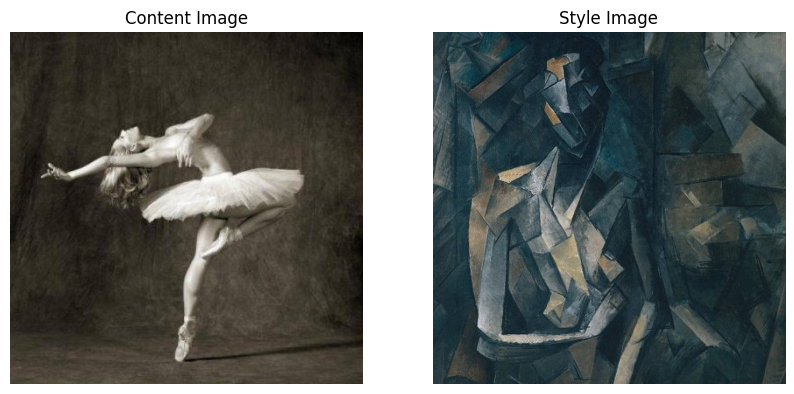

In [10]:
content_img = Image.open("content.jpg").convert("RGB")
style_img = Image.open("style.jpg").convert("RGB")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(content_img)
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(style_img)
plt.title("Style Image")
plt.axis("off")

plt.show()

In [11]:
import torchvision.transforms as transforms

# Select device
device = torch.device("cpu")

# Define image transformation
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Convert images into tensors
content_tensor = transform(content_img).unsqueeze(0).to(device)
style_tensor = transform(style_img).unsqueeze(0).to(device)

print("Images converted into tensors successfully!")
print("Content image shape:", content_tensor.shape)
print("Style image shape:", style_tensor.shape)

Images converted into tensors successfully!
Content image shape: torch.Size([1, 3, 256, 256])
Style image shape: torch.Size([1, 3, 256, 256])


In [12]:
# Use VGG19 feature extraction layers
vgg_features = vgg.features.to(device).eval()

# Define style and content layers
style_layers = [1, 6, 11, 20, 29]
content_layers = [22]

# Function to extract features
def get_features(image, model):
    features = {}

    x = image

    for name, layer in model._modules.items():
        x = layer(x)

        if int(name) in style_layers:
            features[f"style_{name}"] = x

        if int(name) in content_layers:
            features[f"content_{name}"] = x

    return features

print("VGG19 feature extraction function created successfully!")

VGG19 feature extraction function created successfully!


In [13]:
# Function to calculate Gram Matrix
def gram_matrix(tensor):
    batch, channels, height, width = tensor.size()

    features = tensor.view(batch, channels, height * width)

    gram = torch.bmm(features, features.transpose(1, 2))

    return gram / (channels * height * width)


# Extract features from original images
content_features = get_features(content_tensor, vgg_features)
style_features = get_features(style_tensor, vgg_features)

# Store target content features
content_target = content_features["content_22"].detach()

# Store target style Gram matrices
style_targets = {
    layer: gram_matrix(style_features[layer]).detach()
    for layer in style_features
    if layer.startswith("style")
}

print("Content and style features extracted successfully!")
print("Style layers:", list(style_targets.keys()))

Content and style features extracted successfully!
Style layers: ['style_1', 'style_6', 'style_11', 'style_20', 'style_29']


In [14]:
import torch.nn as nn
import torch.optim as optim

# Initialize generated image using content image
generated_image = content_tensor.clone().requires_grad_(True)

# Define optimizer
optimizer = optim.Adam([generated_image], lr=0.003)

# Set loss weights
content_weight = 1
style_weight = 1000000

# Calculate style and content loss
def calculate_loss(generated_features):

    content_loss = nn.functional.mse_loss(
        generated_features["content_22"],
        content_target
    )

    style_loss = 0

    for layer in style_targets:
        generated_gram = gram_matrix(generated_features[layer])

        style_loss += nn.functional.mse_loss(
            generated_gram,
            style_targets[layer]
        )

    total_loss = (
        content_weight * content_loss +
        style_weight * style_loss
    )

    return total_loss, content_loss, style_loss


print("Style transfer optimization process is ready!")

Style transfer optimization process is ready!


In [15]:
# Freeze VGG19 model parameters
for param in vgg_features.parameters():
    param.requires_grad_(False)

# Run style transfer optimization
epochs = 20

print("Starting Neural Style Transfer...\n")

for epoch in range(epochs):

    optimizer.zero_grad()

    # Extract features from generated image
    generated_features = get_features(
        generated_image, vgg_features
    )

    # Calculate losses
    total_loss, content_loss, style_loss = calculate_loss(
        generated_features
    )

    # Backpropagation
    total_loss.backward()

    # Update generated image
    optimizer.step()

    # Keep image values within a reasonable range
    with torch.no_grad():
        generated_image.clamp_(-3, 3)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Total Loss: {total_loss.item():.4f}"
        )

print("\nNeural Style Transfer completed!")

Starting Neural Style Transfer...

Epoch [5/20] Total Loss: 25.4763
Epoch [10/20] Total Loss: 19.9547
Epoch [15/20] Total Loss: 16.4956
Epoch [20/20] Total Loss: 14.2702

Neural Style Transfer completed!


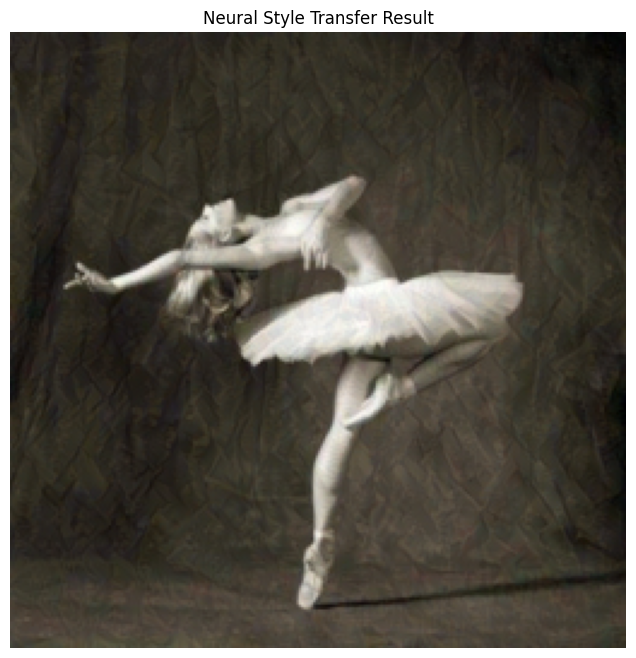

In [16]:
# Convert generated tensor into displayable image
output = generated_image.detach().squeeze(0).cpu()

# Reverse normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

output = output * std + mean
output = output.clamp(0, 1)

# Display final image
plt.figure(figsize=(8, 8))
plt.imshow(output.permute(1, 2, 0).numpy())
plt.title("Neural Style Transfer Result")
plt.axis("off")
plt.show()

In [17]:
epochs = 100

print("Improving Neural Style Transfer...\n")

for epoch in range(epochs):

    optimizer.zero_grad()

    generated_features = get_features(
        generated_image, vgg_features
    )

    total_loss, content_loss, style_loss = calculate_loss(
        generated_features
    )

    total_loss.backward()
    optimizer.step()

    with torch.no_grad():
        generated_image.clamp_(-3, 3)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {total_loss.item():.4f}"
        )

print("Improved style transfer completed!")

Improving Neural Style Transfer...

Epoch [20/100] Loss: 10.2425
Epoch [40/100] Loss: 8.6054
Epoch [60/100] Loss: 7.6722
Epoch [80/100] Loss: 7.0215
Epoch [100/100] Loss: 6.5096
Improved style transfer completed!


In [19]:
from PIL import Image

# Save generated image
final_image = output.permute(1, 2, 0).numpy()
final_image = (final_image * 255).astype("uint8")

Image.fromarray(final_image).save("Neural_Style_Transfer_Result.png")

print("Final image saved successfully!")

Final image saved successfully!


In [20]:
import os

print("File exists:", os.path.exists("Neural_Style_Transfer_Result.png"))
print("File size:", os.path.getsize("Neural_Style_Transfer_Result.png"), "bytes")

File exists: True
File size: 110906 bytes


In [22]:
from google.colab import files

files.download("Neural_Style_Transfer_Result.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Conclusion

#The Neural Style Transfer project was successfully implemented using Python, PyTorch and a pretrained VGG19 model.
#Two images were used: a content image and a style image. The model extracted features from both images and used optimization techniques to combine the content
#of one image with the artistic style of the other.

#The project demonstrates how deep learning and convolutional neural networks can be used to create artistic images by transferring visual styles.